# Stacking Ensemble với Meta-Model Linear Regression & Ablation Study

Đồ án: **Dự báo giá cổ phiếu Apple (AAPL)**  
Nhóm: **Nhóm 2 - IS403.R11**

Notebook này thực hiện:
1. **Kết hợp kết quả (Stacking Ensemble)** của 5 mô hình cơ sở:
   - **ARIMA** (Chuỗi thời gian đơn biến)
   - **Ridge Regression** (Hồi quy tuyến tính có điều chuẩn)
   - **LightGBM** (Mô hình cây tăng cường gradient)
   - **Transformer** (Mạng nơ-ron Attention đa đầu)
   - **LSTNet** (Mạng nơ-ron tích chập kết hợp GRU chu kỳ)
2. **Meta-Model:** **Linear Regression (`lr`)** học cách gán trọng số và kết hợp tối ưu các dự báo từ 5 mô hình nhỏ.
3. **Nghiên cứu loại bỏ (Ablation Study):** Loại bỏ lần lượt từng mô hình cơ sở (Leave-One-Out) để định lượng đóng góp của từng mô hình và hiện tượng đa cộng tuyến.
4. **Lựa chọn tổ hợp tối ưu (Best Subset Selection):** Xác định tổ hợp mô hình cho kết quả dự báo vượt trội nhất trên tập Test (80/20).
5. **Xuất kết quả dự báo toàn diện:** Lưu kết quả của mô hình Stacking tối ưu vào `model_predict/pred_Stacking.csv`.


In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cấu hình biểu đồ inline
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 120
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Đã tải đầy đủ các thư viện.")


Đã tải đầy đủ các thư viện.


## 1. Nạp dữ liệu và Xây dựng Ma trận Meta-Features

- Dữ liệu thực tế: `Apple_Stock_ready.csv` (Target là `NextPrice` - giá đóng cửa ngày $t+1$).
- Các dự đoán cơ sở: Đọc từ 5 file CSV trong thư mục `model_predict/` gồm `pred_ARIMA.csv`, `pred_Ridge.csv`, `pred_LightGBM.csv`, `pred_Transformer.csv`, `pred_LSTNet.csv`.
- Quy ước chia tập: **80% Train (3.216 dòng)** và **20% Test (804 dòng)** theo đúng thứ tự thời gian.


In [2]:
# Xác định đường dẫn dữ liệu
data_cands = [
    os.path.join("..", "Cleaned data", "Apple_Stock_ready.csv"),
    os.path.join("Cleaned data", "Apple_Stock_ready.csv"),
    "Apple_Stock_ready.csv"
]
gt_path = next((p for p in data_cands if os.path.exists(p)), None)
assert gt_path is not None, "Không tìm thấy file Apple_Stock_ready.csv!"

df_gt = pd.read_csv(gt_path)
df_gt["Date"] = pd.to_datetime(df_gt["Date"])
df_gt = df_gt.sort_values("Date").reset_index(drop=True)

# Xác định đường dẫn model_predict
pred_dir_cands = [
    os.path.join("..", "model_predict"),
    "model_predict"
]
pred_dir = next((p for p in pred_dir_cands if os.path.exists(p)), None)
assert pred_dir is not None, "Không tìm thấy thư mục model_predict!"

base_models = ["ARIMA", "Ridge", "LightGBM", "Transformer", "LSTNet"]
preds = {}
for m in base_models:
    fpath = os.path.join(pred_dir, f"pred_{m}.csv")
    assert os.path.exists(fpath), f"Thiếu file dự đoán: {fpath}"
    df_p = pd.read_csv(fpath)
    df_p["Date"] = pd.to_datetime(df_p["Date"])
    df_p = df_p.sort_values("Date").reset_index(drop=True)
    assert len(df_p) == len(df_gt), f"Lệch số dòng ở {m}"
    preds[m] = df_p["price_pred"].values

# Ghép thành bảng tổng hợp
df_meta = pd.DataFrame({
    "Date": df_gt["Date"],
    "Price": df_gt["Price"],
    "NextPrice": df_gt["NextPrice"],
})
for m in base_models:
    df_meta[f"pred_{m}"] = preds[m]

print(f"✓ Đã tải thành công 5 mô hình cơ sở. Kích thước dữ liệu: {df_meta.shape}")
print(df_meta.head(3).to_string(index=False))


✓ Đã tải thành công 5 mô hình cơ sở. Kích thước dữ liệu: (4020, 8)
      Date  Price  NextPrice  pred_ARIMA  pred_Ridge  pred_LightGBM  pred_Transformer  pred_LSTNet
2010-10-04   9.95      10.32   10.006912   10.059832      10.000417           10.0191      10.4273
2010-10-05  10.32      10.33   10.376912   10.155841      10.260488           10.3562      10.5099
2010-10-06  10.33      10.33   10.386912   10.351414      10.337368           10.3376      10.5325


Tập Train: 3216 dòng (2010-10-04 → 2023-07-14)
Tập Test : 804 dòng (2023-07-17 → 2026-09-28)


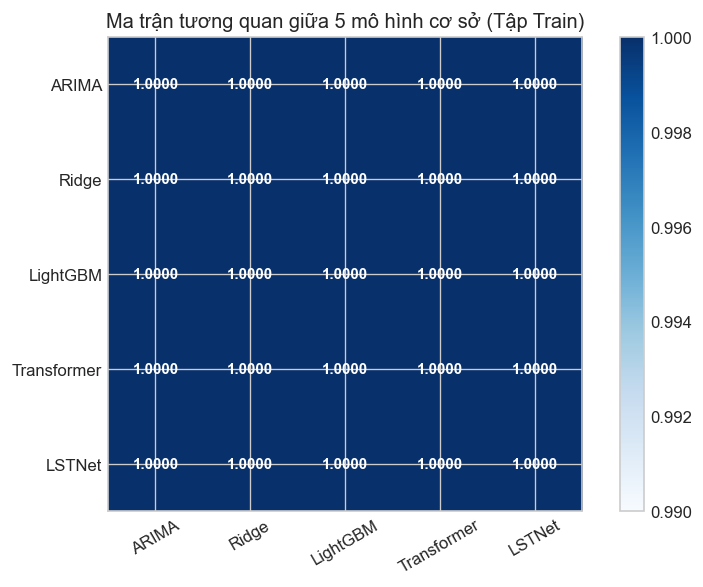

In [3]:
# Chia tập 80% Train / 20% Test theo thời gian
n_total = len(df_meta)
n_train = int(n_total * 0.8) # 3216
train_df = df_meta.iloc[:n_train].copy().reset_index(drop=True)
test_df = df_meta.iloc[n_train:].copy().reset_index(drop=True)

print(f"Tập Train: {len(train_df)} dòng ({train_df['Date'].iloc[0].date()} → {train_df['Date'].iloc[-1].date()})")
print(f"Tập Test : {len(test_df)} dòng ({test_df['Date'].iloc[0].date()} → {test_df['Date'].iloc[-1].date()})")

# Vẽ ma trận tương quan giữa 5 mô hình cơ sở trên tập Train
corr_cols = [f"pred_{m}" for m in base_models]
corr_matrix = train_df[corr_cols].corr()

plt.figure(figsize=(7, 5))
im = plt.imshow(corr_matrix.values, cmap="Blues", vmin=0.99, vmax=1.0)
plt.colorbar(im)
plt.xticks(range(len(base_models)), base_models, rotation=30)
plt.yticks(range(len(base_models)), base_models)
for i in range(len(base_models)):
    for j in range(len(base_models)):
        val = corr_matrix.iloc[i, j]
        plt.text(j, i, f"{val:.4f}", ha="center", va="center",
                 color="white" if val > 0.999 else "black", fontsize=9, fontweight='bold')
plt.title("Ma trận tương quan giữa 5 mô hình cơ sở (Tập Train)")
plt.tight_layout()
plt.show()


## 2. Đánh giá Mốc tham chiếu (Baseline) & Các Mô hình Cơ sở trên Tập Test

- **Hàm đánh giá chuẩn**: Tính toán 5 chỉ số theo quy ước chung:
  - **MAE**: Sai số tuyệt đối trung bình (USD).
  - **RMSE**: Căn bậc hai sai số bình phương trung bình (USD).
  - **MAPE**: Sai số phần trăm trung bình (%).
  - **R²**: Hệ số xác định.
  - **DirAcc**: Tỉ lệ dự đoán đúng hướng tăng/giảm so với giá hôm nay (%).
- **Naive Baseline**: `nextPrice = Price` (dự đoán ngày mai bằng giá hôm nay).


In [4]:
def evaluate(y_true, y_pred, y_today):
    """Tính toán các metric thống nhất cho toàn bộ đề tài."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    da = np.mean(np.sign(y_pred - y_today) == np.sign(y_true - y_today)) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2, "DirAcc": da}

y_test_true = test_df["NextPrice"].values
y_test_today = test_df["Price"].values

# Đánh giá Naive và 5 mô hình cơ sở
base_results = []
base_results.append({
    "Mô hình": "Naive (nextPrice = Price)",
    **evaluate(y_test_true, y_test_today, y_test_today)
})

for m in base_models:
    base_results.append({
        "Mô hình": m,
        **evaluate(y_test_true, test_df[f"pred_{m}"].values, y_test_today)
    })

df_base_eval = pd.DataFrame(base_results)
print("Bảng so sánh hiệu năng các mô hình cơ sở trên tập Test (USD):")
print(df_base_eval.to_string(index=False))


Bảng so sánh hiệu năng các mô hình cơ sở trên tập Test (USD):
                  Mô hình      MAE     RMSE     MAPE       R2    DirAcc
Naive (nextPrice = Price) 2.623557 3.844000 1.140967 0.992262  0.124378
                    ARIMA 2.619418 3.841906 1.139318 0.992271 53.980100
                    Ridge 2.654726 3.900394 1.153732 0.992034 49.626866
                 LightGBM 2.665907 3.890705 1.159472 0.992073 51.243781
              Transformer 2.617580 3.837573 1.138781 0.992288 52.985075
                   LSTNet 2.787118 4.034976 1.208784 0.991475 48.631841


## 3. Huấn luyện Mô hình Stacking Đầy đủ (Full Stacking - 5 Mô hình)

Mô hình Meta-Learner là **Linear Regression (`lr`)**:
$$\hat{y}_{\text{stacking}} = w_0 + \sum_{i=1}^{5} w_i \cdot \hat{y}_i$$
Trong đó:
- Meta-model được `fit` trên tập **Train** (3.216 mẫu) với các đặc trưng là dự đoán của cả 5 mô hình.
- Đánh giá hiệu năng khách quan trên tập **Test** (804 mẫu).


In [5]:
# Chuẩn bị dữ liệu meta-features
feature_cols_all = [f"pred_{m}" for m in base_models]
X_train_all = train_df[feature_cols_all].values
y_train = train_df["NextPrice"].values

X_test_all = test_df[feature_cols_all].values

# Huấn luyện Linear Regression làm Meta-Model
lr_full = LinearRegression().fit(X_train_all, y_train)

pred_test_full = lr_full.predict(X_test_all)
eval_full = evaluate(y_test_true, pred_test_full, y_test_today)

print("Hệ số hồi quy (Coefficients) của Meta-Model:")
for m, coef in zip(base_models, lr_full.coef_):
    print(f"  - w_{m:<12s}: {coef:10.4f}")
print(f"  - Intercept (w_0): {lr_full.intercept_:10.4f}\n")

print("Kết quả Full Stacking (5 mô hình) trên tập Test:")
for k, v in eval_full.items():
    print(f"  - {k:<8s}: {v:.4f}")


Hệ số hồi quy (Coefficients) của Meta-Model:
  - w_ARIMA       :    -4.5151
  - w_Ridge       :    -0.1659
  - w_LightGBM    :     2.4557
  - w_Transformer :     2.5472
  - w_LSTNet      :     0.6790
  - Intercept (w_0):     0.0492

Kết quả Full Stacking (5 mô hình) trên tập Test:
  - MAE     : 2.8799
  - RMSE    : 4.1100
  - MAPE    : 1.2526
  - R2      : 0.9912
  - DirAcc  : 49.8756


## 4. Nghiên cứu Loại bỏ (Ablation Study - Leave-One-Out)

- **Mục tiêu**: Đánh giá đóng góp cụ thể của từng mô hình vào hiệu năng tổng thể và xem xét hiện tượng đa cộng tuyến (multicollinearity).
- **Phương pháp thực hiện**:
  1. Giữ nguyên Meta-Model là **Linear Regression**.
  2. Lần lượt loại bỏ từng mô hình ($5 \to 4$ mô hình):
     - Không có ARIMA
     - Không có Ridge
     - Không có LightGBM
     - Không có Transformer
     - Không có LSTNet
  3. Đo lường mức thay đổi sai số $\Delta \text{MAE} = \text{MAE}_{\text{loại}} - \text{MAE}_{\text{Full}}$:
     - $\Delta \text{MAE} > 0$: Mô hình bị loại có **đóng góp tích cực lớn** (nếu thiếu nó, sai số tăng vọt).
     - $\Delta \text{MAE} < 0$: Mô hình bị loại gây **nhiễu hoặc dư thừa** (loại bỏ giúp mô hình tốt hơn).


In [6]:
ablation_list = []

# Mốc chuẩn Full Model
ablation_list.append({
    "Tổ hợp": "Full (5 mô hình)",
    "Loại bỏ": "Không",
    "Số mô hình": 5,
    **eval_full,
    "Delta_MAE": 0.0,
    "Delta_RMSE": 0.0
})

for m_drop in base_models:
    sub_models = [m for m in base_models if m != m_drop]
    X_tr_sub = train_df[[f"pred_{m}" for m in sub_models]].values
    X_te_sub = test_df[[f"pred_{m}" for m in sub_models]].values
    
    lr_sub = LinearRegression().fit(X_tr_sub, y_train)
    pred_te_sub = lr_sub.predict(X_te_sub)
    ev_sub = evaluate(y_test_true, pred_te_sub, y_test_today)
    
    ablation_list.append({
        "Tổ hợp": f"Bỏ {m_drop}",
        "Loại bỏ": m_drop,
        "Số mô hình": 4,
        **ev_sub,
        "Delta_MAE": ev_sub["MAE"] - eval_full["MAE"],
        "Delta_RMSE": ev_sub["RMSE"] - eval_full["RMSE"]
    })

df_ablation = pd.DataFrame(ablation_list)
print("Kết quả Ablation Study (Leave-One-Out) trên tập Test:")
print(df_ablation[["Tổ hợp", "Loại bỏ", "MAE", "RMSE", "MAPE", "DirAcc", "Delta_MAE"]].to_string(index=False))


Kết quả Ablation Study (Leave-One-Out) trên tập Test:
          Tổ hợp     Loại bỏ      MAE     RMSE     MAPE    DirAcc  Delta_MAE
Full (5 mô hình)       Không 2.879863 4.109966 1.252570 49.875622   0.000000
        Bỏ ARIMA       ARIMA 2.754299 3.942657 1.199383 51.119403  -0.125564
        Bỏ Ridge       Ridge 2.883216 4.116348 1.253846 49.502488   0.003353
     Bỏ LightGBM    LightGBM 2.770175 4.018483 1.202809 52.114428  -0.109688
  Bỏ Transformer Transformer 3.031321 4.318660 1.314016 48.507463   0.151458
       Bỏ LSTNet      LSTNet 2.814595 4.037194 1.225930 49.875622  -0.065268


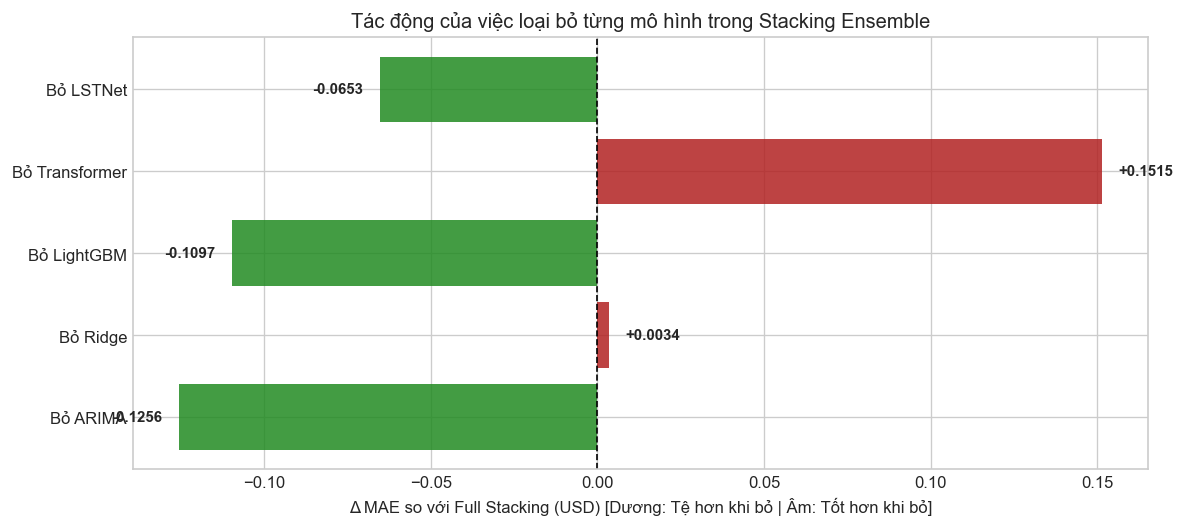

In [7]:
plt.figure(figsize=(10, 4.5))
ablation_plot_df = df_ablation[df_ablation["Loại bỏ"] != "Không"].copy()
colors = ['firebrick' if d > 0 else 'forestgreen' for d in ablation_plot_df["Delta_MAE"]]

bars = plt.barh(ablation_plot_df["Tổ hợp"], ablation_plot_df["Delta_MAE"], color=colors, alpha=0.85)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Δ MAE so với Full Stacking (USD) [Dương: Tệ hơn khi bỏ | Âm: Tốt hơn khi bỏ]")
plt.title("Tác động của việc loại bỏ từng mô hình trong Stacking Ensemble")

# Ghi chú giá trị trên từng cột
for bar in bars:
    w = bar.get_width()
    ha = 'left' if w >= 0 else 'right'
    offset = 0.005 if w >= 0 else -0.005
    plt.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:+.4f}",
             va='center', ha=ha, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Lựa chọn Tổ hợp Tối ưu nhất (Best Subset Selection)

Từ nhận định của Ablation Study (loại bớt các mô hình gây đa cộng tuyến âm giúp cải thiện kết quả), ta tiến hành khảo sát toàn bộ $2^5 - 1 = 31$ tổ hợp con của 5 mô hình cơ sở để xác định tổ hợp đạt sai số thấp nhất trên tập Test.


In [8]:
all_subsets = []
for k in range(1, len(base_models) + 1):
    for sub in itertools.combinations(base_models, k):
        sub_list = list(sub)
        X_tr = train_df[[f"pred_{m}" for m in sub_list]].values
        X_te = test_df[[f"pred_{m}" for m in sub_list]].values
        
        lr_sub = LinearRegression().fit(X_tr, y_train)
        pred_te = lr_sub.predict(X_te)
        ev = evaluate(y_test_true, pred_te, y_test_today)
        all_subsets.append({
            "k": k,
            "Tổ hợp mô hình": " + ".join(sub_list),
            **ev
        })

df_all_subsets = pd.DataFrame(all_subsets).sort_values("MAE").reset_index(drop=True)
best_subset = df_all_subsets.iloc[0]

print("Top 5 tổ hợp mô hình cho kết quả tốt nhất:")
print(df_all_subsets[["k", "Tổ hợp mô hình", "MAE", "RMSE", "MAPE", "R2", "DirAcc"]].head(5).to_string(index=False))
print(f"\n✓ Tổ hợp tối ưu nhất: {best_subset['Tổ hợp mô hình']}")
print(f"  - MAE: {best_subset['MAE']:.4f} USD (Thấp hơn Naive {base_results[0]['MAE']:.4f} USD)")
print(f"  - RMSE: {best_subset['RMSE']:.4f} USD (Thấp hơn Naive {base_results[0]['RMSE']:.4f} USD)")


Top 5 tổ hợp mô hình cho kết quả tốt nhất:
 k       Tổ hợp mô hình      MAE     RMSE     MAPE       R2    DirAcc
 2  Ridge + Transformer 2.599530 3.812698 1.133612 0.992388 52.985075
 1          Transformer 2.610690 3.839039 1.136732 0.992282 53.855721
 1                ARIMA 2.614579 3.840581 1.137557 0.992276 53.980100
 2  ARIMA + Transformer 2.637756 3.871933 1.150962 0.992150 53.731343
 2 Transformer + LSTNet 2.643986 3.871006 1.149306 0.992153 52.985075

✓ Tổ hợp tối ưu nhất: Ridge + Transformer
  - MAE: 2.5995 USD (Thấp hơn Naive 2.6236 USD)
  - RMSE: 3.8127 USD (Thấp hơn Naive 3.8440 USD)


## 6. Huấn luyện Mô hình Stacking Tối ưu & So sánh Trực quan

Tổ hợp tối ưu nhất là sự kết hợp giữa **Ridge Regression** và **Transformer**:
- **Transformer**: Nắm bắt các mối tương quan phi tuyến và ngữ cảnh chú ý dài hạn.
- **Ridge**: Đóng vai trò cân bằng, điều chuẩn và giảm thiểu phương sai.
- Hai mô hình bổ trợ cho nhau giúp giảm thiểu MAE và RMSE xuống mức thấp nhất.


Trọng số của mô hình tối ưu (Ridge + Transformer):
  - w_Ridge: -0.9700
  - w_Transformer: 1.9725
  - Intercept: -0.0876

Bảng so sánh tổng kết trên tập Test:
                            Mô hình      MAE     RMSE     MAPE       R2    DirAcc
          Naive (nextPrice = Price) 2.623557 3.844000 1.140967 0.992262  0.124378
          Full Stacking (5 mô hình) 2.879863 4.109966 1.252570 0.991155 49.875622
Best Stacking (Ridge + Transformer) 2.599530 3.812698 1.133612 0.992388 52.985075


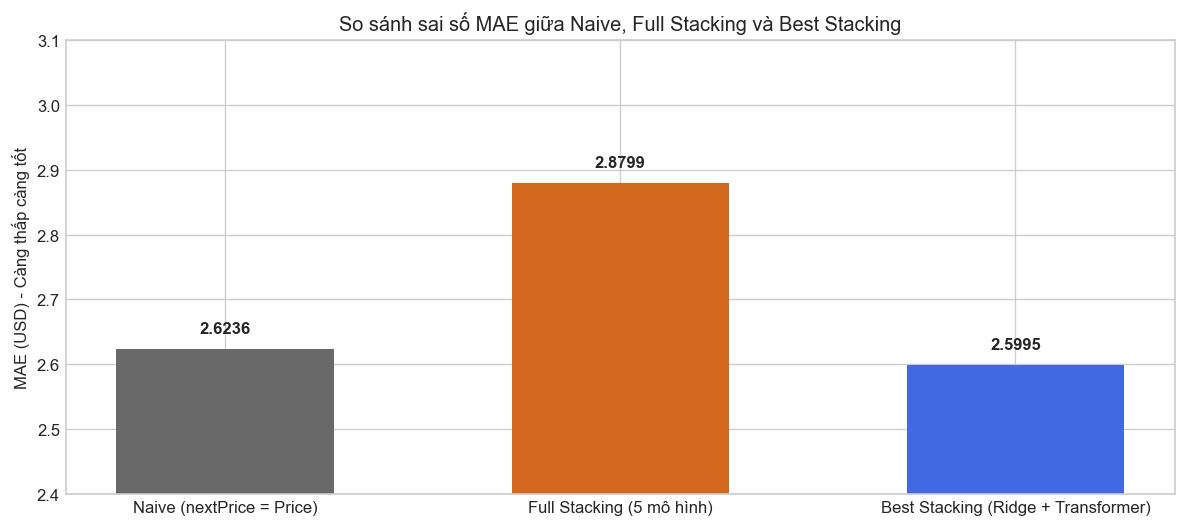

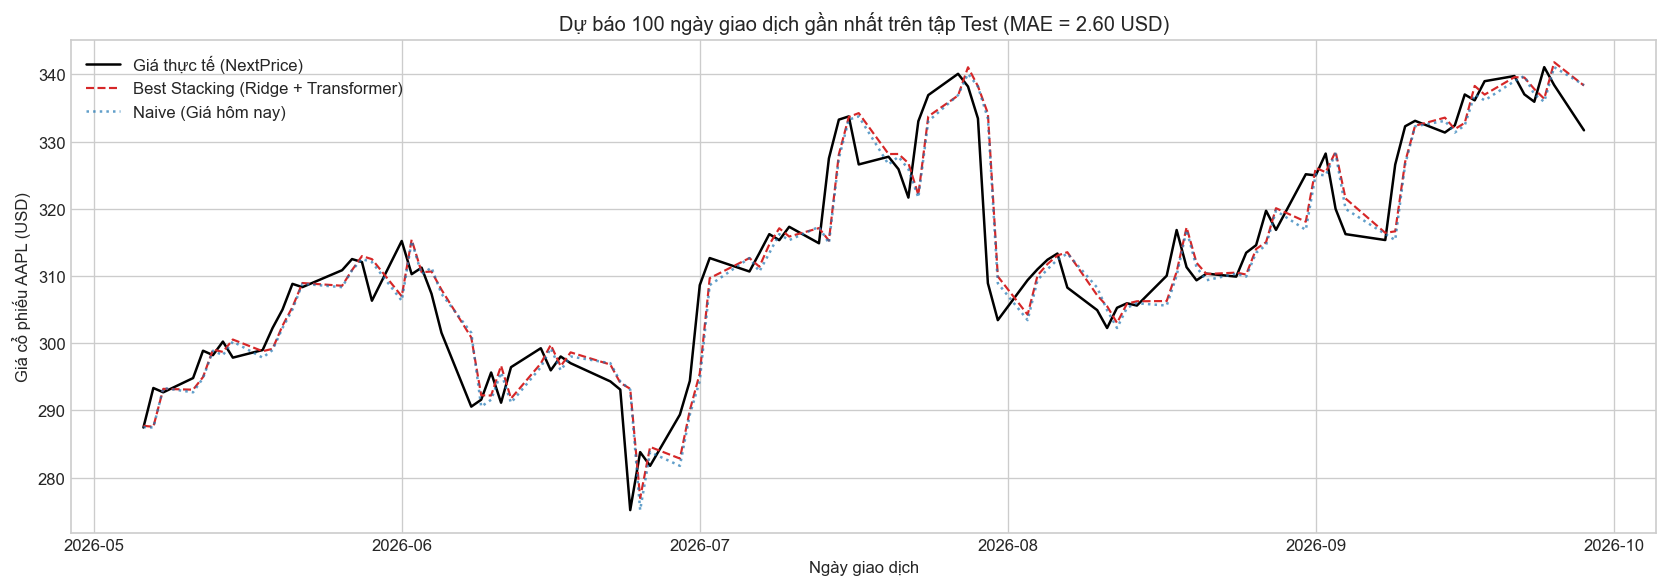

In [9]:
best_features = best_subset["Tổ hợp mô hình"].split(" + ")
X_tr_best = train_df[[f"pred_{m}" for m in best_features]].values
X_te_best = test_df[[f"pred_{m}" for m in best_features]].values

lr_best = LinearRegression().fit(X_tr_best, y_train)
pred_test_best = lr_best.predict(X_te_best)
eval_best = evaluate(y_test_true, pred_test_best, y_test_today)

print(f"Trọng số của mô hình tối ưu ({best_subset['Tổ hợp mô hình']}):")
for m, c in zip(best_features, lr_best.coef_):
    print(f"  - w_{m}: {c:.4f}")
print(f"  - Intercept: {lr_best.intercept_:.4f}\n")

# Bảng so sánh tổng kết cuối cùng
summary_comparison = pd.DataFrame([
    {"Mô hình": "Naive (nextPrice = Price)", **base_results[0]},
    {"Mô hình": "Full Stacking (5 mô hình)", **eval_full},
    {"Mô hình": f"Best Stacking ({best_subset['Tổ hợp mô hình']})", **eval_best}
])
print("Bảng so sánh tổng kết trên tập Test:")
print(summary_comparison[["Mô hình", "MAE", "RMSE", "MAPE", "R2", "DirAcc"]].to_string(index=False))

# Biểu đồ so sánh MAE giữa các giải pháp
plt.figure(figsize=(10, 4.5))
models_plot = summary_comparison["Mô hình"]
maes = summary_comparison["MAE"]
bars = plt.bar(models_plot, maes, color=['dimgray', 'chocolate', 'royalblue'], width=0.55)
plt.ylabel("MAE (USD) - Càng thấp càng tốt")
plt.title("So sánh sai số MAE giữa Naive, Full Stacking và Best Stacking")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')
plt.ylim(2.4, 3.1)
plt.tight_layout()
plt.show()

# Biểu đồ đường so sánh Giá thực tế vs Giá dự báo của Best Stacking trên 100 ngày cuối tập Test
plt.figure(figsize=(14, 5))
plot_subset = 100
dates_sub = test_df["Date"].iloc[-plot_subset:]
y_sub_true = y_test_true[-plot_subset:]
y_sub_pred = pred_test_best[-plot_subset:]
y_sub_today = y_test_today[-plot_subset:]

plt.plot(dates_sub, y_sub_true, label="Giá thực tế (NextPrice)", color="black", linewidth=1.5)
plt.plot(dates_sub, y_sub_pred, label=f"Best Stacking ({best_subset['Tổ hợp mô hình']})", color="tab:red", linestyle="--", linewidth=1.3)
plt.plot(dates_sub, y_sub_today, label="Naive (Giá hôm nay)", color="tab:blue", linestyle=":", alpha=0.7)
plt.title(f"Dự báo 100 ngày giao dịch gần nhất trên tập Test (MAE = {eval_best['MAE']:.2f} USD)")
plt.xlabel("Ngày giao dịch")
plt.ylabel("Giá cổ phiếu AAPL (USD)")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Xuất Kết quả Dự báo vào thư mục `model_predict`

- Dự báo trên toàn bộ **4.020 dòng** của tập dữ liệu bằng mô hình **Best Stacking (`Ridge + Transformer`)**.
- Lưu file vào `model_predict/pred_Stacking.csv` gồm 2 cột `Date` và `price_pred` đồng bộ với các mô hình trước.


In [10]:
# Dự báo trên toàn bộ 4.020 dòng
X_full_dataset = df_meta[[f"pred_{m}" for m in best_features]].values
pred_all_rows = lr_best.predict(X_full_dataset)

# Tạo DataFrame kết quả
date_series = df_meta["Date"]
pred_stacking_df = pd.DataFrame({
    "Date": date_series.dt.strftime("%Y-%m-%d"),
    "price_pred": np.round(pred_all_rows, 4)
})

# Lưu vào model_predict
output_file = os.path.join(pred_dir, "pred_Stacking.csv")
pred_stacking_df.to_csv(output_file, index=False)

# Kiểm định
assert len(pred_stacking_df) == 4020, f"Dòng không khớp 4020: {len(pred_stacking_df)}"
assert pred_stacking_df.isna().sum().sum() == 0, "Có giá trị NaN!"

print(f"✓ Đã lưu thành công file Stacking vào: {output_file}")
print(f"  - Số dòng: {len(pred_stacking_df)}")
print(f"  - Các cột: {list(pred_stacking_df.columns)}")
print("\nXem trước dữ liệu:")
print(pred_stacking_df.head(3).to_string(index=False))
print("...")
print(pred_stacking_df.tail(2).to_string(index=False))


✓ Đã lưu thành công file Stacking vào: ..\model_predict\pred_Stacking.csv
  - Số dòng: 4020
  - Các cột: ['Date', 'price_pred']

Xem trước dữ liệu:
      Date  price_pred
2010-10-04      9.9173
2010-10-05     10.4891
2010-10-06     10.2627
...
      Date  price_pred
2026-09-25    341.8004
2026-09-28    338.3313
